In [2]:
# Imports
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re
import pandas as pd
from io import StringIO
import numpy as np
import plotly.graph_objects as go                                                                                                                                                     

In [3]:
# Plots settings

SOLVER = 'TWNN'
SOLVER_COLORS = {
    "TWNN": "#1f77b4",  
}

BLUE_PALETTE = [
    "#d0e4f7",  # very light
    "#a8cce8",  # light
    "#7ab4d9",  # medium-light
    "#4682b4",  # steelblue
    "#2e5f8a",  # medium-dark
    "#1a3d61",  # dark
]

SOLVER_LABELS = {
    "NearestNeighbor": "Twnn",
}

SIZE_ORDER = ["small", "medium", "big"]

SIZE_LABELS = {
    "small":  "Pequeño (c ≤ 25)",
    "medium": "Mediano (25 < c ≤ 50)",
    "big":    "Grande (50 < c ≤ 80)",
}

SOLVER_BAR_COLORS = {
    "TWNN": ["#1f77b4", "#aec7e8"],  
  }

In [4]:
# import matplotlib.pyplot as plt
# import os

# os.makedirs("figures", exist_ok=True)
# _fig_counter = [0]
# _original_show = plt.show

# def _auto_save_show():
#     _fig_counter[0] += 1
#     plt.savefig(f"/Users/tomasmarmay/Documents/famaf/tesis/src/essay/fig_{_fig_counter[0]:02d}.png", bbox_inches="tight", dpi=150)
#     _original_show()

# plt.show = _auto_save_show

In [5]:
# Load and process data

with open("../../run_results.sql", "r") as f:
    sql = f.read()

# Extraer el bloque COPY de run_results
match = re.search(
    r"COPY public\.run_results \((.+?)\) FROM stdin;\n(.*?)\\\.",
    sql,
    re.DOTALL,
)

columns = [c.strip() for c in match.group(1).split(",")]
data = match.group(2)

df = pd.read_csv(StringIO(data), sep="\t", names=columns, na_values=["\\N"])

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"
    
    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = df['dim'] = c + (2*v)

    df["feasible"] = df["feasible"].map({"t": True, "f": False, True: True, False: False})
    df["valid"] = df["valid"].map({"t": True, "f": False, True: True, False: False})

    return df

df = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing4"))

### 5.1 Análisis individual TWNN

In [10]:
nn = df[df["solver"] == SOLVER].copy()
nn_feasible = nn[nn["feasible"] == True].copy()

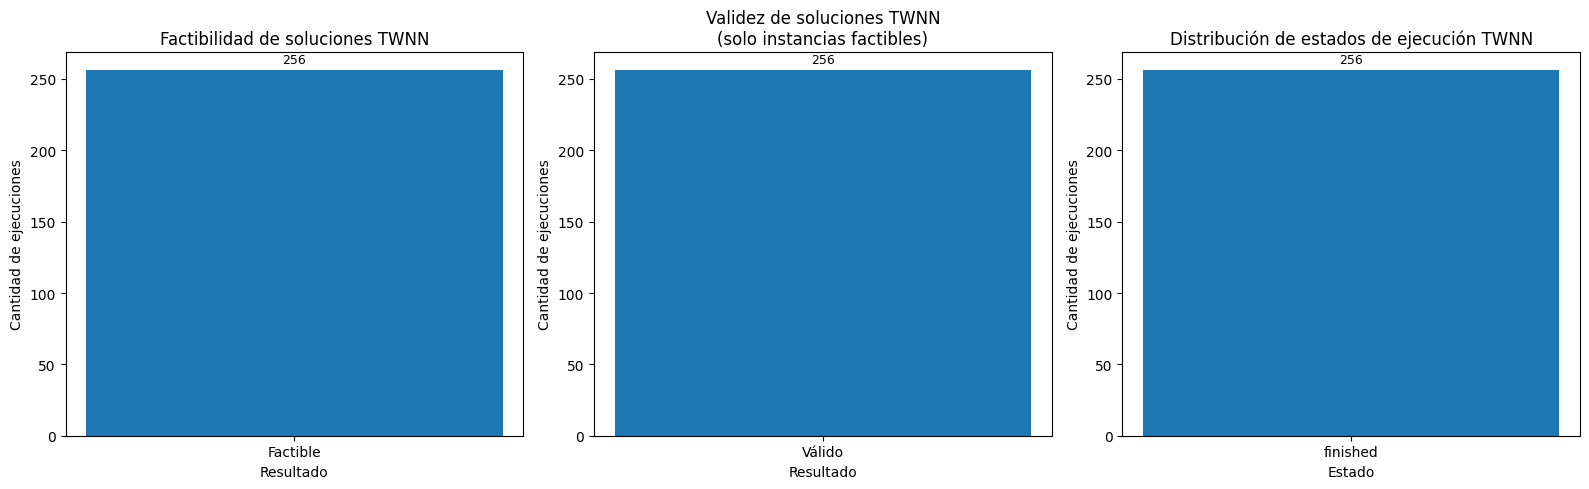

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── Feasible / Infeasible ──────────────────────────────────────────────────────
feasible_counts = nn["feasible"].map({True: "Factible", False: "Infactible"}).value_counts()

axes[0].bar(feasible_counts.index, feasible_counts.values, color=SOLVER_BAR_COLORS[SOLVER])
axes[0].set_title("Factibilidad de soluciones TWNN")
axes[0].set_xlabel("Resultado")
axes[0].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(feasible_counts.items()):
    axes[0].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Valid / Invalid (solo feasibles) ──────────────────────────────────────────
valid_counts = nn_feasible["valid"].map({True: "Válido", False: "Inválido"}).value_counts()

axes[1].bar(valid_counts.index, valid_counts.values, color=SOLVER_BAR_COLORS[SOLVER])
axes[1].set_title("Validez de soluciones TWNN\n(solo instancias factibles)")
axes[1].set_xlabel("Resultado")
axes[1].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(valid_counts.items()):
    axes[1].text(i, val + 5, str(val), ha="center", fontsize=9)

# ── Status distribution ────────────────────────────────────────────────────────
status_counts = nn["status"].value_counts()

axes[2].bar(status_counts.index, status_counts.values, color=SOLVER_BAR_COLORS[SOLVER])
axes[2].set_title("Distribución de estados de ejecución TWNN")
axes[2].set_xlabel("Estado")
axes[2].set_ylabel("Cantidad de ejecuciones")
for i, (label, val) in enumerate(status_counts.items()):
    axes[2].text(i, val + 5, str(val), ha="center", fontsize=9)

plt.tight_layout()
plt.show()

In [7]:
# ── Valores ─────────────────────────────────────────────────────────────────                                                                                                        
def n(mask): return nn[mask].shape[0]                                                                                                                                                 
                                                                                                                                                                                    
total               = nn.shape[0]                                                                                                                                                     
n_finished          = n(nn["status"] == "finished")                                                                                                                                   
n_timeout           = n(nn["status"] == "timeout")                                                                                                                                    
finished_feasible   = n((nn["status"] == "finished") & (nn["feasible"] == True))
finished_infeasible = n((nn["status"] == "finished") & (nn["feasible"] == False))                                                                                                     
feasible_valid      = n((nn["feasible"] == True) & (nn["valid"] == True))
feasible_invalid    = n((nn["feasible"] == True) & (nn["valid"] == False))                                                                                                            
                                                                                                                                                                                    
# ── Nodos: 0=Total, 1=Finished, 2=Timeout,                                                                                                                                           
#           3=Factible, 4=Infactible, 5=Válido, 6=Inválido                                                                                                                            
labels = ["Total", "Finished", "Timeout", "Factible", "Infactible", "Válido", "Inválido"]                                                                                             
source = [0, 0,         1,                1,                  2,        3,              3]                                                                                            
target = [1, 2,         3,                4,                  4,        5,              6]                                                                                            
value  = [n_finished, n_timeout,                                                                                                                                                      
        finished_feasible, finished_infeasible,                                                                                                                                     
        n_timeout,                                                                                                                                                                  
        feasible_valid, feasible_invalid]                                                                                                                                           

pcts = [                                                                                                                                                                              
    100,        
    n_finished / total * 100,
    n_timeout  / total * 100,
    finished_feasible / total * 100,                                                                                                                                                  
    (finished_infeasible + n_timeout) / total * 100,
    feasible_valid   / total * 100,                                                                                                                                                   
    feasible_invalid / total * 100,
]                                                                                                                                                                                     

x = [0.01, 0.33, 0.33, 0.66, 0.66, 0.99, 0.99]                                                                                                                                        
y = [0.40, 0.10, 0.65, 0.15, 0.70, 0.10, 0.55]
x = [.001 if v == 0 else .999 if v == 1 else v for v in x]                                                                                                                            
y = [.001 if v == 0 else .999 if v == 1 else v for v in y]                                                                                                                            
                                                                                                                                                                                    
node_colors = [                                                                                                                                                                       
    BLUE_PALETTE[3],
    BLUE_PALETTE[5], BLUE_PALETTE[2],                                                                                                                                                 
    "#2ecc71", "#e74c3c",
    "#27ae60", "#c0392b",                                                                                                                                                             
]               
                                                                                                                                                                                    
link_colors = [
    "rgba(70,130,180,0.3)",   # Total → Finished                                                                                                                                      
    "rgba(70,130,180,0.3)",   # Total → Timeout
    "rgba(46,204,113,0.3)",   # Finished → Factible
    "rgba(231,76,60,0.3)",    # Finished → Infactible                                                                                                                                 
    "rgba(231,76,60,0.3)",    # Timeout → Infactible
    "rgba(39,174,96,0.3)",    # Factible → Válido                                                                                                                                     
    "rgba(192,57,43,0.3)",    # Factible → Inválido
]                                                                                                                                                                                     
                
# ── Figura ───────────────────────────────────────────────────────────────────                                                                                                       
fig = go.Figure(go.Sankey(
    textfont=dict(color="black", size=12),                                                                                                                                            
    node=dict(
        pad=35, thickness=20,                                                                                                                                                         
        line=dict(color="white", width=1),
        label=[f"{name}<br>{pct:.1f}%" for name, pct in zip(labels, pcts)],
        x=x, y=y,                                                                                                                                                                     
    ),
    link=dict(source=source, target=target, value=value, color=link_colors),                                                                                                          
))                                                                                                                                                                                    

fig.update_layout(                                                                                                                                                                    
    title="<span style='font-size:22px;color:steelblue;'><b>Flujo de ejecuciones TWNN</b></span>",
    font=dict(size=12, color="white"),                                                                                                                                                
    paper_bgcolor="#F8F8FF",
)                                                                                                                                                                                     
fig.update_traces(node_color=node_colors)
fig.show()

/tmp/ipykernel_14831/1314730674.py:17: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



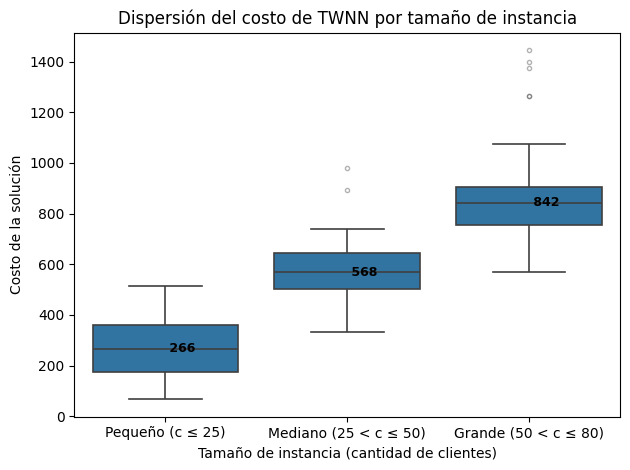

In [8]:
fig, ax = plt.subplots()

sns.boxplot(
    data=nn_feasible,
    x="size",
    y="cost",
    order=SIZE_ORDER,
    color=SOLVER_COLORS[SOLVER],
    linewidth=1.2,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
    ax=ax,
)

ax.set_title("Dispersión del costo de TWNN por tamaño de instancia")
ax.set_xlabel("Tamaño de instancia (cantidad de clientes)")
ax.set_ylabel("Costo de la solución")
ax.set_xticklabels([SIZE_LABELS[s] for s in SIZE_ORDER])

for i, size in enumerate(SIZE_ORDER):
    subset = nn_feasible[nn_feasible["size"] == size]["cost"]
    if not subset.empty:
        median = subset.median()
        ax.text(i, median, f" {median:.0f}", va="center", ha="left",
                fontsize=9, color="black", fontweight="bold")

plt.tight_layout()
plt.show()

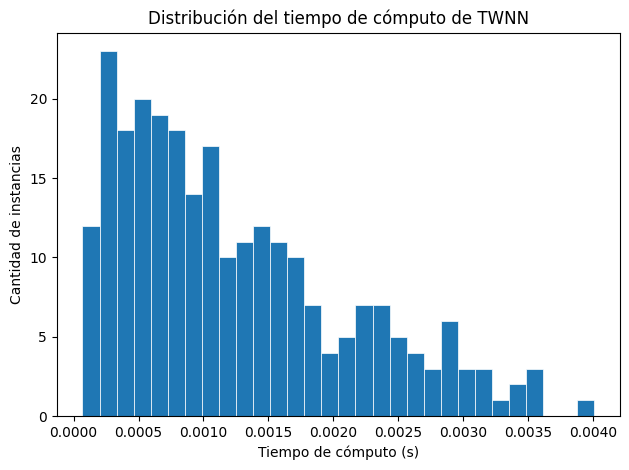

In [9]:
fig, ax = plt.subplots()
ax.hist(nn["runtime"], bins=30, color=SOLVER_COLORS[SOLVER], edgecolor="white", linewidth=0.5)
ax.set_title("Distribución del tiempo de cómputo de TWNN")
ax.set_xlabel("Tiempo de cómputo (s)")
ax.set_ylabel("Cantidad de instancias")
plt.tight_layout()
plt.show()